# IMPORT

In [1]:
import pandas as pd
from pathlib import Path
import os

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt


# FIX FOR THE KMEANS PROBLEM

In [2]:
os.environ["OMP_NUM_THREADS"] = "6" # It does not work T-T

# DEFINE FOLDERS

In [3]:
STATION_FEATURE_FOLDER = Path("../data/station_features")
STATION_CLUSTER_FOLDER = Path("../data/station_clusters")
CLUSTER_SUMMARY_FOLDER = Path("../data/cluster_summary")
CLUSTER_PLOT_FOLDER = Path("../data/cluster_plot")

folders = [STATION_FEATURE_FOLDER, STATION_CLUSTER_FOLDER, CLUSTER_SUMMARY_FOLDER, CLUSTER_PLOT_FOLDER]
for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

# DEFINE CONSTANTS

In [4]:
RANDOM_STATE = 42
K = 2 # Should be choosen after seeing the plot etc, but so far only 2 worked well so

# LOAD DATA

In [5]:
df = pd.read_csv(f"{STATION_FEATURE_FOLDER}/station_features.csv")

print("Stations:", df.shape[0])

Stations: 1417


# ADD A NEW FEATURE

In [6]:
"""
stationcode,mean_usage,std_usage,min_usage,max_usage,mean_weekend,mean_weekday,day_usage,night_usage,daily_amplitude,
corr_weather_temperature_2m,corr_weather_wind_speed_10m,corr_weather_wind_direction_10m,corr_weather_weather_code,latitude,longitude,capacity
"""

"""
corr_weather_temperature_2m     *  +
corr_weather_wind_speed_10m     *  +
corr_weather_wind_direction_10m *  +
corr_weather_weather_code       * 
"""

'\ncorr_weather_temperature_2m     *  +\ncorr_weather_wind_speed_10m     *  +\ncorr_weather_wind_direction_10m *  +\ncorr_weather_weather_code       * \n'

# SELECT FEATURES FOR CLUSTERING

In [7]:
print(df.columns)

Index(['station_code', 'mean_usage', 'std_usage', 'min_usage', 'max_usage',
       'mean_weekend', 'mean_weekday', 'day_usage', 'night_usage',
       'daily_amplitude', 'corr_temperature', 'corr_wind_speed',
       'corr_wind_direction', 'corr_weather_code', 'latitude', 'longitude',
       'capacity'],
      dtype='object')


In [8]:
"""
to exclude:
-stationcode
-latitude / longitude (for now)
-capacity (size != behavior)
"""
# # means we can remove to improve clustering quality
cluster_features = [
    "mean_usage",
    "std_usage", #
    "daily_amplitude", #
    "mean_weekend",
    "mean_weekday",
    "day_usage",
    "night_usage",
    "corr_temperature", #
    "corr_wind_speed", #
    "corr_wind_direction", #
    "corr_weather_code", #
]

cluster_features = [c for c in cluster_features if c in df.columns]

X = df[cluster_features]
print("Clustering features:", cluster_features)

Clustering features: ['mean_usage', 'std_usage', 'daily_amplitude', 'mean_weekend', 'mean_weekday', 'day_usage', 'night_usage', 'corr_temperature', 'corr_wind_speed', 'corr_wind_direction', 'corr_weather_code']


# SCALE FEATURES

In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# CHOOSE NUMBER OF CLUSTERS (ELBOW METHOD)

c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning:

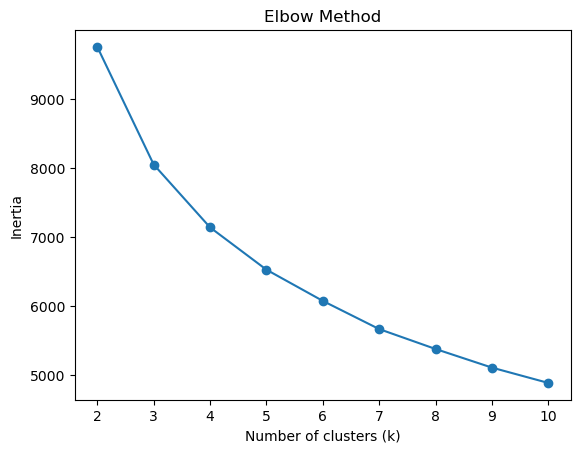

In [10]:
inertias = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure()
plt.plot(K_range, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()


# CHOOSE NUMBER OF CLUSTERS (SILHOUETTE SCORE)

In [11]:
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"k={k} -> silhouette={score:.3f}")

c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=2 -> silhouette=0.338


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=3 -> silhouette=0.325


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=4 -> silhouette=0.292


... (2 outputs left out)

c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=6 -> silhouette=0.197


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=7 -> silhouette=0.218


# FINAL CLUSTERING

In [12]:
kmeans = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=50)
df["cluster"] = kmeans.fit_predict(X_scaled)

print(df["cluster"].value_counts())


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


cluster
0    725
1    692
Name: count, dtype: int64


# SAVE STATION-CLUSTER MAPPING

In [13]:
df[["station_code", "cluster"]].to_csv(
    f"{STATION_CLUSTER_FOLDER}/station_clusters_{K}_{RANDOM_STATE}_{len(cluster_features)}_features.csv", index=False
)

print(f"Saved {STATION_CLUSTER_FOLDER}/station_clusters_{K}_{RANDOM_STATE}_{len(cluster_features)}_features.csv")

Saved ..\data\station_clusters/station_clusters_2_42_11_features.csv


# UNDERSTANDING WHAT EACH CLUSTER MEANS

In [14]:
cluster_summary = (
    df.groupby("cluster")[cluster_features]
    .mean()
    .round(3)
)

cluster_summary.to_csv(f"{CLUSTER_SUMMARY_FOLDER}/cluster_summary_{K}_{RANDOM_STATE}_{len(cluster_features)}_features.csv")
print(cluster_summary)

         mean_usage  std_usage  daily_amplitude  mean_weekend  mean_weekday  \
cluster                                                                       
0             0.247      0.182            0.231         0.256         0.243   
1             0.549      0.248            0.322         0.551         0.549   

         day_usage  night_usage  corr_temperature  corr_wind_speed  \
cluster                                                              
0            0.218        0.264            -0.054           -0.063   
1            0.562        0.542            -0.016            0.036   

         corr_wind_direction  corr_weather_code  
cluster                                          
0                     -0.033              0.022  
1                      0.019              0.010  


# VISUAL CHECK

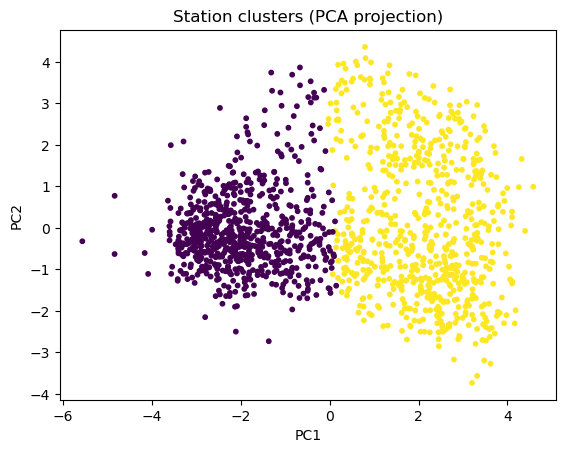

In [15]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure()
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["cluster"], s=10)
plt.title("Station clusters (PCA projection)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.savefig(f"{CLUSTER_PLOT_FOLDER}/station_clusters_pca_{K}_{RANDOM_STATE}_{len(cluster_features)}_features.png", dpi=300, bbox_inches='tight')
plt.show()
